## Basic trip over a single edge (with current)
In this notebook, we set up a basic simulation where one vessel moves over a 1D network path. In this case a current is implemented on the network. The example shows how currents affect travel time. 

In [1]:
# package(s) used for creating and geo-locating the graph
import networkx as nx
from pyproj import Geod
from shapely.geometry import Point

# package(s) related to the simulation (creating the vessel, running the simulation)
import datetime
import simpy
import opentnsim

# OpenTNSim mixins and utils
from opentnsim.core import Identifiable, Movable
from opentnsim.core.logutils import logbook2eventtable
from opentnsim.core.utils import create_object
from opentnsim.core.visualizations import generate_vessel_gantt_chart
from opentnsim.graph.calculations import calculate_distance_along_path
from opentnsim.graph.mixins import DiGraph
from opentnsim.model import Simulation

# package(s) needed for inspecting the output
import pandas as pd


print("This notebook is executed with OpenTNSim version {}".format(opentnsim.__version__))

This notebook is executed with OpenTNSim version 2.3.2a2.dev3+g514a752b4.d20260603


#### 0. Create environment
We create the environment

In [2]:
# create a simpy environment (we also define an start time)
simulation = Simulation(simulation_start = datetime.datetime(2026, 1, 1, 0, 0, 0))
env = simulation.env

#### 1. Create graph
We create the same graph as in notebook 0000, but now directed.

In [3]:
graph = DiGraph() # we need a directed graph as we have different water current velocity directions per edge

In [4]:
# initialize geodetic calculator with WGS84 ellipsoid
geod = Geod(ellps="WGS84")

# starting point (longitude, latitude)
lon0, lat0 = 0, 0

# compute the other point 100 km East from Point 0
lon1, lat1, _ = geod.fwd(lon0, lat0, 90, 100000) # East from Point 0

# define nodes with their geographic coordinates
coords = {
    "0": (lon0, lat0),
    "1": (lon1, lat1),
}

We add these coordinates as nodes to a NetworkX-package graph:

In [5]:
for node_name, coord in coords.items():
    graph.add_node(name = node_name, geometry = Point(coord))

In [6]:
# create list of edges
edges = [("0", "1"), ("1", "0")] # bi-directional edge

# add edges
for edge in edges:
    graph.add_edge(edge)

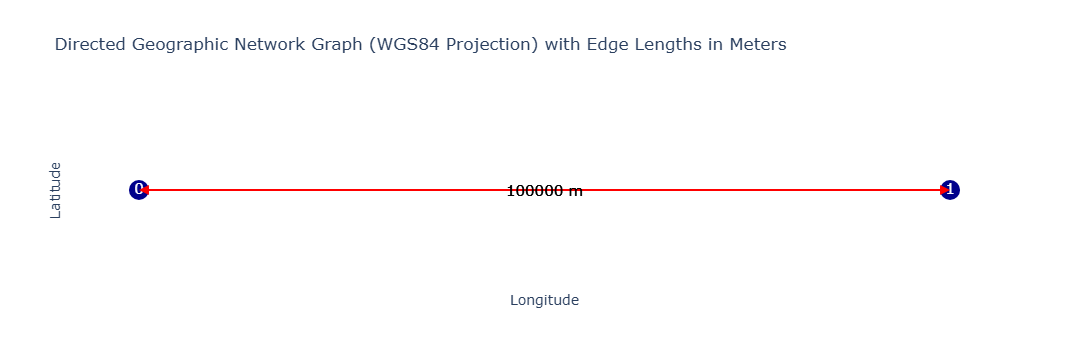

In [7]:
graph.plot()

As an additional step, we add a depth and current to the graph:

In [8]:
GeneralDepth = 10 # m
Current = 1 # m/s

# add graph to environment
graph.edges['0', '1'].update({'GeneralDepth': GeneralDepth, 'Current': -Current}) # from '0' to '1' you sail against the current
graph.edges['1', '0'].update({'GeneralDepth': GeneralDepth, 'Current':  Current}) # from '1' to '0' you sail with the current

We add the graph to the simulation:

In [9]:
simulation.add_graph(graph)

#### 2. Create vessel
We create our vessel type

In [10]:
# make your preferred Vessel class out of available mix-ins.
Vessel = create_object(
    "Vessel", 
    (
        Identifiable, # allows to give the object a name and a random ID,
        Movable,      # allows the object to move, with a fixed speed, while logging this activity
    ), 
)

In [11]:
# create vessel from a dict 
route = nx.dijkstra_path(env.graph, "0", "1")
route.append('0')

data_vessel = {
    "env": env,                                        # needed for simpy simulation
    "name": "Vessel",                                  # required by Identifiable
    "route": route,                                    # required by Routeable
    "v": 3,                                            # required by Movable, 3 m/s to check if the distance is covered in the expected time
}  # 

# create an instance of the Vessel class using the input dict data_vessel
vessel = Vessel(**data_vessel)

In [12]:
# create a mission
def mission(env, vessel):
    """
    Method that defines the mission of the vessel. 
    
    In this case: 
        keep moving along the path until its end point is reached
    """
    while True:
        yield from vessel.move()
        
        if vessel.geometry == nx.get_node_attributes(env.graph, "geometry")[vessel.route[-1]]:
            break

In [13]:
# add vessel to the environment
simulation.add_vessel(vessel, mission)

#### 3. Run simulation

In [14]:
simulation.run()

#### 4. Inspect output
We can now inspect  the simulation output by inspecting the _vessel.logbook_. Note that the _Log_ mix-in was included when we added _Movable_. The _vessel.logbook_ keeps track of the moving activities of the vessel. For each discrete event OpenTNSim logs an event message, the start/stop time and the location. The _vessel.logbook_ is of type dict. For convenient inspection it can be loaded into a Pandas dataframe. 

In [15]:
# load the logbook data into a dataframe
df = pd.DataFrame.from_dict(vessel.logbook)

print("'{}' logbook data:".format(vessel.name))  
print('')

display(df)

trip_distance = calculate_distance_along_path(env.graph, vessel.route)
trip_duration = datetime.timedelta.total_seconds(vessel.logbook[-1]['Timestamp'] - vessel.logbook[0]['Timestamp'])

print("'{}' travelled a distance of {:.1f} meters".format(vessel.name, trip_distance))
print("'{}' took {:.1f} seconds to arrive at its destination".format(vessel.name, trip_duration))  
print("'{}' travelled at an average speed of {:.1f} meters per second".format(vessel.name, trip_distance/trip_duration))
print('')
print('')

'Vessel' logbook data:



,Message,Timestamp,Value,Geometry
0,Sailing from node 0 to node 1 start,2026-01-01 00:00:00,0.0,POINT (0 0)
1,Sailing from node 0 to node 1 stop,2026-01-01 13:53:20,100000.0,POINT (0.8983152841195217 0)
2,Sailing from node 1 to node 0 start,2026-01-01 13:53:20,100000.0,POINT (0.8983152841195217 0)
3,Sailing from node 1 to node 0 stop,2026-01-01 20:50:00,200000.0,POINT (0 0)


'Vessel' travelled a distance of 200000.0 meters
'Vessel' took 75000.0 seconds to arrive at its destination
'Vessel' travelled at an average speed of 2.7 meters per second




We can create an eventtable of the logbook:

In [16]:
df_eventtable = logbook2eventtable([vessel])
df_eventtable

,object id,object name,main activity name,subactivity name,start location,stop location,start time,stop time,distance (m),duration (s)
0,3731330c-c025-4896-b19f-eac0c12c7228,Vessel,Sailing from node 0 to node 1,,POINT (0 0),POINT (0.8983152841195217 0),2026-01-01 00:00:00,2026-01-01 13:53:20,100000.0,50000.0
1,3731330c-c025-4896-b19f-eac0c12c7228,Vessel,Sailing from node 1 to node 0,,POINT (0.8983152841195217 0),POINT (0 0),2026-01-01 13:53:20,2026-01-01 20:50:00,100000.0,25000.0


And plot this eventtable as a Gantt-chart:

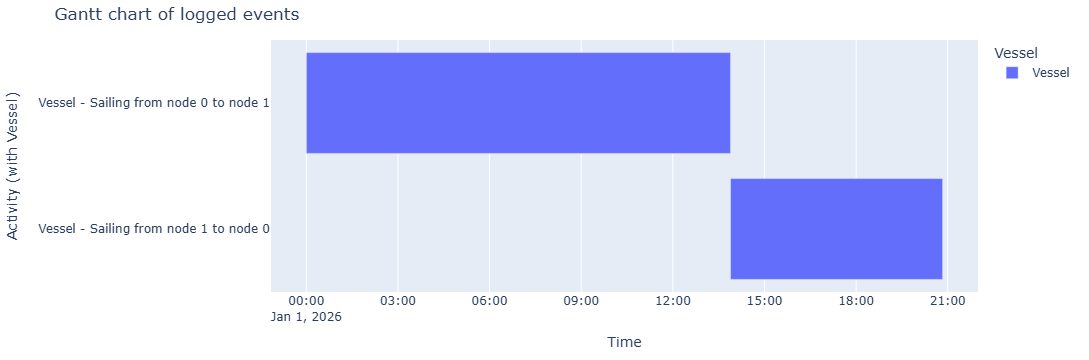

In [17]:
generate_vessel_gantt_chart(df_eventtable)

We observe that the upstream trip now, expectedly, takes longer than the downstream trip: 50000.0 s (with a speed of 2.0 m/s over ground: 3.0 - 1.0 m/s) compared to 25000.0 s (with a speed of 4.0 m/s over ground: 3.0 + 1.0 m/s)